# 02 · Extraire les compétences des offres

Les offres du service public ont parfois un texte « compétences attendues » (69 000 annonces, surtout à l'État et à
l'hôpital). Ce texte est libre : listes à puces, phrases, rubriques « Savoir-être », niveaux « maîtrise / expertise »...
L'objectif de cette étape est d'en tirer une liste de compétences **comparables d'une offre à l'autre**, en les rattachant
au référentiel ROME 4.0 de France Travail, puis d'étendre l'estimation aux 1,6 million d'offres via leur métier.

Plan :
1. Découper les textes en items.
2. Rattacher chaque item au ROME : cinq méthodes sans clé d'API.
3. Les évaluer sur un échantillon annoté à l'aveugle.
4. Tester un reclassement par LLM.
5. Rattacher les métiers aux fiches ROME.
6. Ce que donne la méthode retenue sur toutes les offres.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import polars as pl

from offres import competences as comp, donnees, graphiques as g

g.style()
pl.Config.set_tbl_rows(25)
pl.Config.set_fmt_str_lengths(70)
EVAL = donnees.CACHE.parent / "evaluation"
CLAIR = "#a9cbf2"  # même bleu, éclairci : « partiel » sous « correct »
offres = donnees.offres_service_public()


# Intervalle de confiance à 95 % d'un taux pondéré, par bootstrap sur les items (tirés selon leur poids)
def intervalle(ok, poids, n=2000, graine=0):
    rng = np.random.default_rng(graine)
    ok, poids = np.asarray(ok, float), np.asarray(poids, float)
    tirages = rng.choice(len(ok), size=(n, len(ok)), p=poids / poids.sum())
    return np.percentile(ok[tirages].mean(axis=1), [2.5, 97.5])

## 1. Du texte libre aux items

`comp.segmenter` coupe aux retours à la ligne, points-virgules et puces (y compris les puces Wingdings collées depuis
Word), retire les titres de rubrique (« Savoirs théoriques et pratiques : », « Niveau maîtrise ») et les niveaux accolés
(« Management : expertise » → « Management »), et éclate les listes de mots courts (« Autonome, rigoureux, dynamique »)
sans couper les phrases. `comp.normaliser` produit une forme de comparaison : minuscules, sans accents, sans « bonne
connaissance de », « capacité à », « (indispensable) ».

In [2]:
exemple = offres.filter(pl.col("competences_texte").str.contains("Niveau ma")).row(0, named=True)["competences_texte"]
print(exemple[:600])
print("\n→", comp.segmenter(exemple)[:12])

Connaissances techniques

Savoir-faire

Savoir-être

Connaître l'environnement professionnel
Niveau maîtrise requis	Savoir travailler en équipe
Niveau maîtrise requis	Savoir accueillir
Niveau expert requis
Avoir des compétences en informatique
Niveau maîtrise requis	Savoir appliquer la réglementation
Niveau pratique à acquérir	Sens des relations humaines
Niveau expert requis
Connaissance de la réglementation en SST
Niveau maîtrise requis	Savoir s'organiser
Niveau maîtrise requis	Savoir s'adapter
Niveau expert requis

Avoir l'esprit de synthèse
Niveau maîtrise requis	

Sen

→ ["Connaître l'environnement professionnel", 'Savoir travailler en équipe', 'Savoir accueillir', 'Avoir des compétences en informatique', 'Savoir appliquer la réglementation', 'Sens des relations humaines', 'Connaissance de la réglementation en SST', "Savoir s'organiser", "Savoir s'adapter", "Avoir l'esprit de synthèse", 'Sens de la pédagogie', 'Savoir analyser']


69,007 annonces, 640,399 items, 125,158 formes distinctes, 9.3 items par annonce


forme,len
str,u32
"""rigueur""",16739
"""travail en equipe""",16088
"""organisation et methode""",13318
"""autonomie""",11548
"""analyse""",6379
"""utilisation des logiciels de bureautique""",6336
"""utilisation d un systeme d information specifique ou lie a son domaine…",5961
"""sens des relations humaines""",5718
"""reactivite""",5559


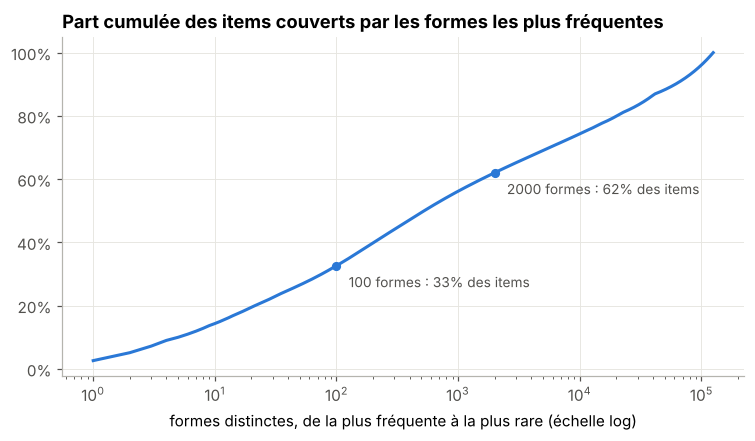

In [3]:
items = comp.items_des_offres(offres)
formes = items.group_by("forme").len().sort("len", descending=True)
print(f"{items['annonce_id'].n_unique():,} annonces, {items.height:,} items, {formes.height:,} formes distinctes, "
      f"{items.height / items['annonce_id'].n_unique():.1f} items par annonce")
part = formes["len"].cum_sum() / formes["len"].sum()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, formes.height + 1), part, color=g.PALETTE[0])
ax.set_xscale("log")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
for n in (100, 2000):
    ax.annotate(f"{n} formes : {part[n - 1]:.0%} des items", (n, part[n - 1]), xytext=(8, -14), textcoords="offset points",
                fontsize=9, color="#52514e")
    ax.plot(n, part[n - 1], "o", color=g.PALETTE[0], ms=5)
ax.set_xlabel("formes distinctes, de la plus fréquente à la plus rare (échelle log)")
ax.set_title("Part cumulée des items couverts par les formes les plus fréquentes")
g.enregistrer(fig, "09_concentration_items")
formes.head(15)

Le vocabulaire est très concentré : une centaine de formes (« rigueur », « travail en équipe », « organisation et
méthode », « autonomie »...) couvre un tiers des items. Elles viennent pour beaucoup du référentiel des compétences des
ministères, repris tel quel dans les offres de l'État. La longue traîne (plus de 80 000 formes vues une seule fois) est
faite d'items spécifiques (« cytométrie en flux », « règles de chancellerie ») : c'est là que le rattachement est difficile.

## 2. Rattacher les items au ROME

Le catalogue cible réunit les 20 072 savoir-faire, 16 savoir-être et 15 699 savoirs du ROME 4.0, avec leur rattachement
(domaine, enjeu, macro-compétence). Cinq méthodes, toutes sans clé d'API :

| Méthode | Principe | Forces | Faiblesses |
|---|---|---|---|
| dictionnaire | forme identique | sûr | ne trouve presque rien |
| TF-IDF | n-grammes de caractères (3 à 5) | robuste aux fautes, capitales, pluriels | mots communs trompeurs (« expression écrite » → « expression théâtrale ») |
| e5 / MiniLM | modèles de phrases multilingues, plus proche voisin | capte le sens | faux amis sur les mots isolés (« rigueur » → « accrocheur-rigger ») |
| hybride | somme des scores TF-IDF et embeddings centrés-réduits | combine les deux | |

Un détail a compté : les textes en capitales (« RIGUEUR », « REACTIVITE ») dégradent les modèles de phrases, d'où
`comp.nettoyer` (minuscules, accents gardés) avant l'encodage.

In [4]:
items_eval = pl.read_csv(EVAL / "competences_items.csv")
props = pl.read_csv(EVAL / "competences_propositions.csv", schema_overrides={"code_ogr": pl.Utf8})
exemples = ["RIGUEUR", "REACTIVITE", "EXPRESSION ECRITE", "MANAGEMENT", "SENS DES RELATIONS HUMAINES"]
(props.join(items_eval.select("id", "item"), on="id")
 .filter(pl.col("item").is_in(exemples), pl.col("methode").is_in(["tfidf", "e5", "hybride_e5"]))
 .select("item", "methode", "libelle_rome", "verdict").sort("item", "methode"))

item,methode,libelle_rome,verdict
str,str,str,str
"""EXPRESSION ECRITE""","""e5""","""Ecriture web""","""partiel"""
"""EXPRESSION ECRITE""","""hybride_e5""","""Expression théâtrale""","""faux"""
"""EXPRESSION ECRITE""","""tfidf""","""Expression théâtrale""","""faux"""
"""MANAGEMENT""","""e5""","""Management stratégique""","""partiel"""
"""MANAGEMENT""","""hybride_e5""","""Techniques de management""","""correct"""
"""MANAGEMENT""","""tfidf""","""Techniques de management""","""correct"""
"""REACTIVITE""","""e5""","""Réaction chimique""","""faux"""
"""REACTIVITE""","""hybride_e5""","""Faire preuve de réactivité""","""correct"""
"""REACTIVITE""","""tfidf""","""Faire preuve de réactivité""","""correct"""


## 3. Évaluation sur un échantillon annoté à l'aveugle

Protocole (détails dans `evaluation/README.md`) :
- 400 items tirés au hasard parmi les 657 000 découpés avant dédoublonnage (321 formes distinctes), pour que les
  métriques reflètent la distribution réelle ;
- pour chaque item, la meilleure proposition de chaque méthode, mélangées, sans dire qui propose quoi ;
- verdict `correct` (même compétence), `partiel` (même domaine, plus large ou plus étroit) ou `faux` ;
- deux annotateurs indépendants, 41 items en commun pour mesurer l'accord ; les propositions apparues plus tard (après
  une correction du nettoyage, ou choisies par un LLM) ont été jugées par d'autres annotateurs, mêlées à des
  propositions déjà jugées pour vérifier qu'ils notent pareil.

**Transparence** : les annotateurs sont des instances de Claude, pas des humains. Les verdicts sont publiés et relisibles,
et ce notebook se recalcule à partir d'eux.

In [5]:
import json
from sklearn.metrics import cohen_kappa_score

brutes = json.load(open(EVAL / "annotations_brutes.json"))
rang = {"faux": 0, "partiel": 1, "correct": 2}
A = {d["id"]: d for d in brutes["A"]}
B = {d["id"]: d for d in brutes["B"]}
a, b = zip(*[(rang[A[i]["verdicts"][k]], rang[B[i]["verdicts"][k]]) for i in set(A) & set(B) for k in A[i]["verdicts"]])
print(f"{len(set(A) & set(B))} items, {len(a)} propositions annotées deux fois : accord {np.mean(np.array(a) == np.array(b)):.0%}, "
      f"kappa de Cohen {cohen_kappa_score(a, b):.2f} (pondéré {cohen_kappa_score(a, b, weights='linear'):.2f})")
from sklearn.metrics import confusion_matrix
print("Lignes : annotateur A, colonnes : annotateur B (faux, partiel, correct)")
print(confusion_matrix(a, b))
non_comp = items_eval.filter(~pl.col("est_competence"))["poids"].sum() / items_eval["poids"].sum()
print(f"Items qui ne sont pas des compétences (fragments, rubriques, contrat) : {non_comp:.1%}")

41 items, 127 propositions annotées deux fois : accord 93%, kappa de Cohen 0.88 (pondéré 0.90)
Lignes : annotateur A, colonnes : annotateur B (faux, partiel, correct)
[[56  0  0]
 [ 7 50  2]
 [ 0  0 12]]
Items qui ne sont pas des compétences (fragments, rubriques, contrat) : 4.5%


nom,couverture,correct,ic_bas,ic_haut,correct_ou_partiel
str,f64,f64,f64,f64,f64
"""Claude, candidats hybride MiniLM""",0.91623,0.589005,0.531353,0.640264,0.905759
"""Claude, candidats hybride e5""",0.921466,0.528796,0.471947,0.584158,0.910995
"""Hybride TF-IDF + MiniLM""",1.0,0.382199,0.330033,0.435726,0.787958
"""Hybride TF-IDF + e5""",1.0,0.361257,0.310231,0.415842,0.774869
"""e5""",1.0,0.348168,0.293729,0.40264,0.704188
"""TF-IDF""",1.0,0.348168,0.29703,0.40264,0.748691
"""MiniLM""",1.0,0.308901,0.257426,0.363036,0.646597
"""e5 (asymétrique)""",1.0,0.308901,0.257426,0.363036,0.649215
"""Dictionnaire""",0.070681,0.070681,0.042904,0.10231,0.070681


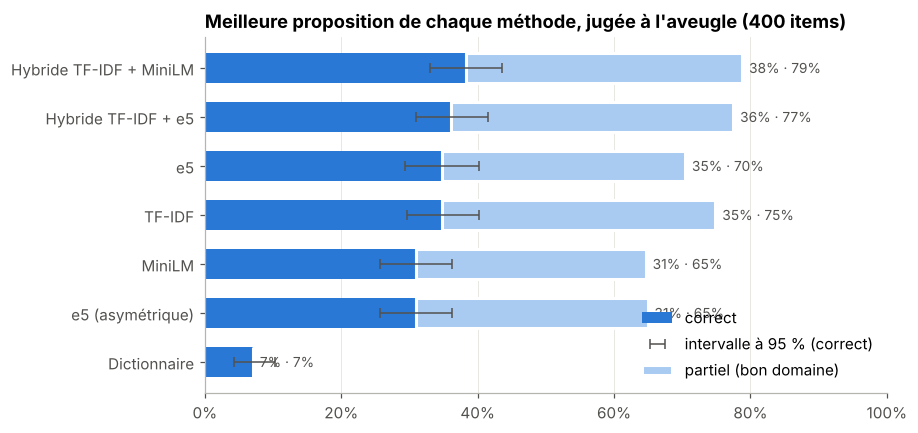

In [6]:
NOMS = {"dictionnaire": "Dictionnaire", "tfidf": "TF-IDF", "e5_asym": "e5 (asymétrique)", "e5": "e5", "minilm": "MiniLM",
        "hybride_e5": "Hybride TF-IDF + e5", "hybride_minilm": "Hybride TF-IDF + MiniLM",
        "llm_claude": "Claude, candidats hybride e5", "llm_claude_minilm": "Claude, candidats hybride MiniLM"}
ev = props.join(items_eval.select("id", "poids", "est_competence"), on="id").filter("est_competence")
total = items_eval.filter("est_competence")["poids"].sum()
res = (ev.group_by("methode").agg(
        correct=((pl.col("verdict") == "correct") * pl.col("poids")).sum() / total,
        partiel=((pl.col("verdict") == "partiel") * pl.col("poids")).sum() / total,
        couverture=pl.col("poids").sum() / total)
       .with_columns(correct_ou_partiel=pl.col("correct") + pl.col("partiel"), nom=pl.col("methode").replace(NOMS))
       .sort("correct"))
# Intervalles de confiance du taux « correct » : une ligne par item compétence, 0 si la méthode ne propose rien
base = items_eval.filter("est_competence").select("id", "poids")
ic = {m: intervalle(base.join(ev.filter(pl.col("methode") == m).select("id", "verdict"), on="id", how="left")
                    ["verdict"].eq("correct").fill_null(False).to_numpy(), base["poids"].to_numpy())
      for m in res["methode"]}
res = res.with_columns(ic_bas=pl.col("methode").replace_strict({m: v[0] for m, v in ic.items()}),
                       ic_haut=pl.col("methode").replace_strict({m: v[1] for m, v in ic.items()}))
sans_llm = res.filter(~pl.col("methode").str.starts_with("llm"))
fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(sans_llm.height)
ax.barh(y, sans_llm["correct"], color=g.PALETTE[0], height=0.6, label="correct")
ax.errorbar(sans_llm["correct"], y, xerr=[sans_llm["correct"] - sans_llm["ic_bas"], sans_llm["ic_haut"] - sans_llm["correct"]],
            fmt="none", ecolor="#52514e", elinewidth=1, capsize=3, label="intervalle à 95 % (correct)")
ax.barh(y, sans_llm["partiel"], left=sans_llm["correct"], color=CLAIR, height=0.6, label="partiel (bon domaine)",
        edgecolor="white", linewidth=2)
ax.set_yticks(y, sans_llm["nom"])
for yy, c, cp in zip(y, sans_llm["correct"], sans_llm["correct_ou_partiel"]):
    ax.text(cp + 0.01, yy, f"{c:.0%} · {cp:.0%}", va="center", fontsize=9, color="#52514e")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("Meilleure proposition de chaque méthode, jugée à l'aveugle (400 items)")
g.enregistrer(fig, "10_evaluation_methodes")
res.select("nom", "couverture", "correct", "ic_bas", "ic_haut", "correct_ou_partiel").sort("correct", descending=True)

- Le **dictionnaire** est sûr mais inutile : 7 % des items seulement ont une forme identique dans le ROME.
- Chaque méthode seule trouve la compétence exacte pour 31 à 35 % des items. Les **embeddings seuls ne font pas mieux
  que TF-IDF**, et le placent moins souvent dans le bon domaine (65 à 70 % contre 75 %) : sur des items très courts, ils
  se laissent prendre aux faux amis. L'usage symétrique de e5 (« query: » des deux côtés) vaut mieux que l'usage
  asymétrique prévu pour la recherche.
- L'**hybride** combine les deux : 36 à 38 % de compétences exactes, 78 à 79 % dans le bon domaine. Avec 400 tirages,
  l'incertitude est de ±5 points : les deux hybrides sont à égalité, et leur avance sur TF-IDF seul est réelle surtout
  au niveau du domaine. Celui avec e5 est retenu parce qu'un seul modèle suffit alors pour les items et les métiers
  (section 5, où les deux font jeu égal).
- Le plafond est bas : même en prenant la meilleure de toutes les propositions, moins de la moitié des items ont un
  équivalent exact dans le ROME. Beaucoup d'items sont composés (« autonomie et rigueur ») ou plus fins que le
  référentiel, d'où la place du verdict `partiel` : au niveau du domaine ou de la macro-compétence, le rattachement est
  fiable trois fois sur quatre.

Le score de l'hybride sert-il de niveau de confiance ? On trie les items par score et on regarde la précision quand on ne
garde que les plus sûrs.

PosixPath('/home/user/offres-emploi-competences/rapports/figures/11_precision_couverture.png')

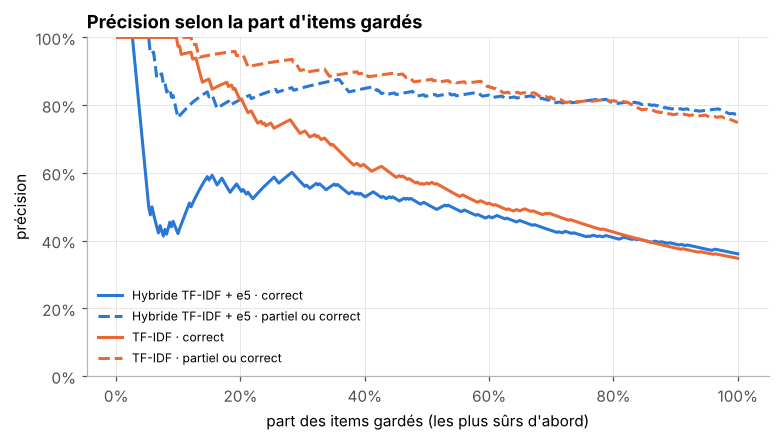

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
for i, m in enumerate(["hybride_e5", "tfidf"]):
    d = ev.filter(pl.col("methode") == m).sort("score", descending=True)
    w = d["poids"].to_numpy()
    cumw = np.cumsum(w)
    cov = cumw / total
    for verdicts, style in (({"correct"}, "-"), ({"correct", "partiel"}, "--")):
        ok = np.cumsum(w * d["verdict"].is_in(list(verdicts)).to_numpy())
        ax.plot(cov, ok / cumw, style, color=g.PALETTE[i], label=f"{NOMS[m]} · {' ou '.join(sorted(verdicts, reverse=True))}")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_ylim(0, 1)
ax.set_xlabel("part des items gardés (les plus sûrs d'abord)")
ax.set_ylabel("précision")
ax.legend(fontsize=8, loc="lower left")
ax.set_title("Précision selon la part d'items gardés")
g.enregistrer(fig, "11_precision_couverture")

Le score de l'hybride aide un peu (les 20 % d'items qu'il juge les plus sûrs sont exacts une fois sur deux). Celui de
TF-IDF trie bien mieux : ses 20 % les plus sûrs sont exacts quatre fois sur cinq, car un score TF-IDF élevé veut dire
que les mots de l'item se retrouvent presque tels quels dans le libellé ROME. Pour une analyse qui ne voudrait que des
rattachements sûrs, c'est ce filtre qu'il faudrait utiliser ; ici tous les rattachements sont gardés, et les analyses
agrègent au niveau du domaine et de la macro-compétence, où la méthode est fiable.

## 4. Un LLM fait-il mieux ?

Consigne du projet : n'ajouter un LLM que s'il apporte un gain mesurable. Test : pour chaque item, un LLM choisit la
meilleure des 10 propositions de l'hybride, ou aucune si rien ne convient (`offres.reclassement`, même consigne pour
tous les modèles). Ses choix nouveaux ont été annotés à l'aveugle, mêlés à des propositions déjà jugées. Le test a été
fait deux fois avec Claude : sur les candidats de l'hybride e5 (ceux de la production) et, plus tôt, sur ceux de
l'hybride MiniLM.

In [8]:
res.filter(pl.col("methode").str.contains("hybride|llm")).select(
    "nom", "couverture", "correct", "ic_bas", "ic_haut", "correct_ou_partiel").sort("correct", descending=True)

nom,couverture,correct,ic_bas,ic_haut,correct_ou_partiel
str,f64,f64,f64,f64,f64
"""Claude, candidats hybride MiniLM""",0.91623,0.589005,0.531353,0.640264,0.905759
"""Claude, candidats hybride e5""",0.921466,0.528796,0.471947,0.584158,0.910995
"""Hybride TF-IDF + MiniLM""",1.0,0.382199,0.330033,0.435726,0.787958
"""Hybride TF-IDF + e5""",1.0,0.361257,0.310231,0.415842,0.774869


Le gain est net : **53 à 59 % de compétences exactes au lieu de 36 à 38 %, 91 % dans le bon domaine au lieu de 78 %**.
L'écart entre les deux passages de Claude (53 et 59 %) est de l'ordre de l'incertitude : il faut lire « un peu plus d'une
compétence sur deux ». Le LLM écarte aussi 17 ou 18 des 18 items parasites (fragments, titres), que les autres méthodes
rattachent quand même. Deux réserves : le test a été fait avec un modèle haut de gamme, et le reclasseur comme les
annotateurs sont des modèles de la même famille, ce qui peut flatter le résultat.

En production, il faudrait une clé d'API (secret GitHub) : environ 125 000 formes × 10 propositions ≈ 20 millions de
jetons au premier passage, soit 1 à 3 $ avec Claude Haiku 5.5 en mode batch, puis quelques centimes par semaine pour
les formes nouvelles. Ce n'est pas branché à ce stade : le pipeline publié reste sans clé, et ce résultat est présenté
comme une amélioration mesurée.

## 5. Rattacher les métiers aux fiches ROME

Le texte de compétences ne couvre que 4,5 % des offres. Pour les autres, on prête à chaque offre les compétences de la
fiche ROME de son métier : il faut donc rattacher les 885 métiers du répertoire de la fonction publique aux 13 855
appellations du ROME. Les libellés à double genre (« Chargée / Chargé de paie ») sont ramenés à une forme
(`comp.sans_double_genre`) avant la comparaison.

nom,correct,correct_ou_partiel,correct_top60_pondere,ic_bas,ic_haut,large_top60_pondere
str,f64,f64,f64,f64,f64,f64
"""Hybride TF-IDF + e5""",0.46,0.88,0.586154,0.466667,0.7,0.923771
"""e5""",0.38,0.73,0.502629,0.383333,0.616667,0.786214
"""Hybride TF-IDF + MiniLM""",0.45,0.88,0.500824,0.366667,0.616667,0.931443
"""TF-IDF""",0.45,0.87,0.478696,0.35,0.6,0.923771
"""MiniLM""",0.3,0.73,0.336255,0.216667,0.45,0.775759


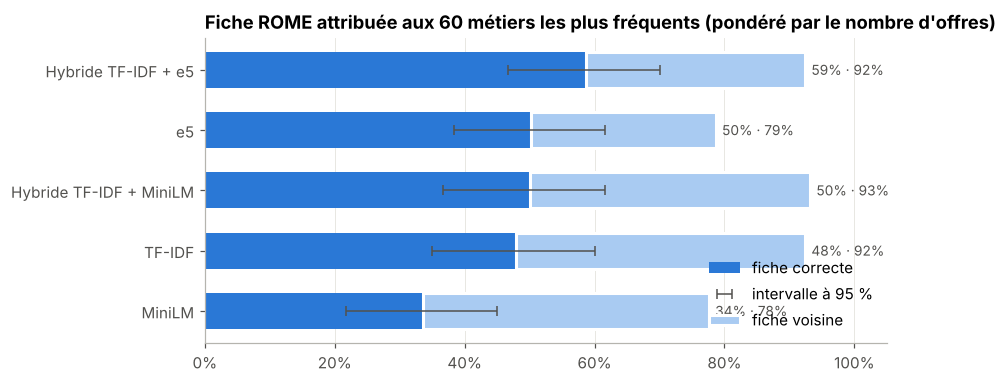

In [9]:
met = pl.read_csv(EVAL / "metiers_propositions.csv")
NOMS_M = {"tfidf": "TF-IDF", "e5": "e5", "minilm": "MiniLM", "hybride_e5": "Hybride TF-IDF + e5", "hybride_minilm": "Hybride TF-IDF + MiniLM"}
def taux(d, poids):
    w = pl.col(poids)
    return d.group_by("methode").agg(correct=((pl.col("verdict") == "correct") * w).sum() / w.sum(),
                                     correct_ou_partiel=((pl.col("verdict") != "faux") * w).sum() / w.sum())
r100 = taux(met.with_columns(un=pl.lit(1)), "un")
r60 = taux(met.filter("top60"), "offres").rename({"correct": "correct_top60_pondere", "correct_ou_partiel": "large_top60_pondere"})
rm = r100.join(r60, on="methode").with_columns(nom=pl.col("methode").replace(NOMS_M)).sort("correct_top60_pondere")
ic_m = {m: intervalle(d["verdict"].eq("correct").to_numpy(), d["offres"].to_numpy())
        for m, d in ((m, met.filter("top60", pl.col("methode") == m)) for m in rm["methode"])}
rm = rm.with_columns(ic_bas=pl.col("methode").replace_strict({m: v[0] for m, v in ic_m.items()}),
                     ic_haut=pl.col("methode").replace_strict({m: v[1] for m, v in ic_m.items()}))
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(rm.height)
ax.barh(y, rm["correct_top60_pondere"], color=g.PALETTE[0], height=0.6, label="fiche correcte")
ax.errorbar(rm["correct_top60_pondere"], y, xerr=[rm["correct_top60_pondere"] - rm["ic_bas"], rm["ic_haut"] - rm["correct_top60_pondere"]],
            fmt="none", ecolor="#52514e", elinewidth=1, capsize=3, label="intervalle à 95 %")
ax.barh(y, rm["large_top60_pondere"] - rm["correct_top60_pondere"], left=rm["correct_top60_pondere"], color=CLAIR,
        height=0.6, label="fiche voisine", edgecolor="white", linewidth=2)
ax.set_yticks(y, rm["nom"])
for yy, c, cp in zip(y, rm["correct_top60_pondere"], rm["large_top60_pondere"]):
    ax.text(cp + 0.01, yy, f"{c:.0%} · {cp:.0%}", va="center", fontsize=9, color="#52514e")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlim(0, 1.05)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("Fiche ROME attribuée aux 60 métiers les plus fréquents (pondéré par le nombre d'offres)")
g.enregistrer(fig, "12_evaluation_metiers")
rm.select("nom", "correct", "correct_ou_partiel", "correct_top60_pondere", "ic_bas", "ic_haut", "large_top60_pondere").sort(
    "correct_top60_pondere", descending=True)

L'hybride TF-IDF + e5 attribue une fiche correcte à 59 % des offres des métiers fréquents, et une fiche au moins voisine
à 92 %. L'écart avec l'autre hybride n'est pas significatif : les deux ne diffèrent que sur deux des 60 métiers, dont
« Chargée / Chargé de gestion administrative », qui pèse à lui seul 86 000 offres ; sans pondération, ils sont à 55 et
53 %. Les intervalles de confiance, larges (±15 points), le rappellent : 60 métiers, c'est peu. Les erreurs restantes tiennent souvent au référentiel : certains métiers propres à l'administration
(« Instruction et délivrance des titres », « Gestionnaire de scolarité ») n'ont pas d'équivalent dans le ROME.

## 6. La méthode retenue sur toutes les offres

`offres competences` (workflow « Compétences », après chaque mise à jour des offres) applique l'hybride TF-IDF + e5 à
toutes les formes et à tous les métiers, et publie `competences_formes.parquet`, `competences_items.parquet` et
`metiers_rome.parquet` dans la release `donnees`.

In [10]:
formes_rome = pl.read_parquet(donnees.chemin("competences_formes.parquet"))
items_offres = pl.read_parquet(donnees.chemin("competences_items.parquet"))
metiers_rome = pl.read_parquet(donnees.chemin("metiers_rome.parquet"))
catalogue = comp.catalogue_rome()
competences_offres = (items_offres.join(formes_rome.select("forme", "code_ogr", "score"), on="forme")
                      .join(catalogue.select("code_ogr", "libelle", "type", "domaine_competence", "libelle_macro_competence"),
                            on="code_ogr", how="left"))
n_annonces = competences_offres["annonce_id"].n_unique()
print(f"{n_annonces:,} annonces, {competences_offres.height:,} rattachements, "
      f"{competences_offres['code_ogr'].n_unique():,} compétences ROME distinctes")
competences_offres.group_by("type").agg(pl.col("annonce_id").n_unique().alias("annonces")).with_columns(
    part=pl.col("annonces") / n_annonces).sort("annonces", descending=True)

68,998 annonces, 637,684 rattachements, 14,954 compétences ROME distinctes


type,annonces,part
str,u32,f64
"""Savoir""",66515,0.964013
"""Savoir-faire""",60064,0.870518
"""Savoir-être professionnel""",14225,0.206165


PosixPath('/home/user/offres-emploi-competences/rapports/figures/13_competences_top.png')

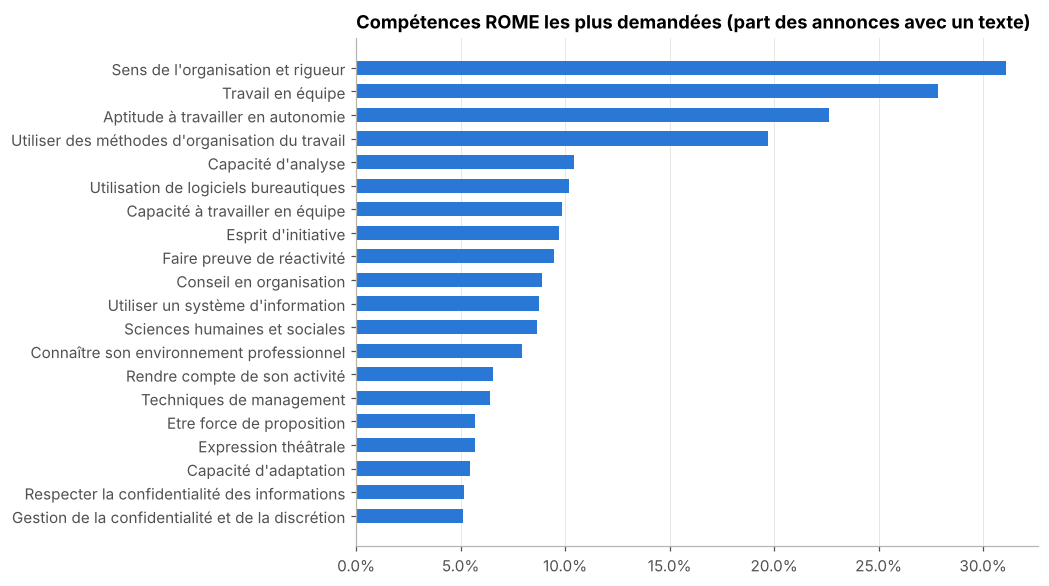

In [11]:
top = (competences_offres.group_by("libelle").agg(pl.col("annonce_id").n_unique().alias("annonces"))
       .sort("annonces", descending=True).head(20).reverse())
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["libelle"], top["annonces"] / n_annonces, color=g.PALETTE[0], height=0.6)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.grid(axis="y", visible=False)
ax.set_title("Compétences ROME les plus demandées (part des annonces avec un texte)")
g.enregistrer(fig, "13_competences_top")

En tête viennent des qualités personnelles (rigueur, travail en équipe, autonomie, esprit d'initiative) : ce sont elles
que les recruteurs écrivent le plus souvent. Le ROME en range la plupart parmi ses « savoirs », d'où la part de ce type
dans le tableau ci-dessus. Seuls les savoir-faire ont un domaine dans l'arborescence ROME (les savoirs et savoir-être n'en ont
pas) : les tableaux par domaine qui suivent ne portent donc que sur les savoir-faire. Le domaine « Développement
économique » y pèse lourd surtout parce qu'il contient « Utiliser des méthodes d'organisation du travail », la forme
la plus fréquente des « sens de l'organisation » écrits dans les offres : un domaine se lit à travers ses
macro-compétences, pas à son seul intitulé.

In [12]:
dom = (competences_offres.drop_nulls("domaine_competence").group_by("domaine_competence")
       .agg(pl.col("annonce_id").n_unique().alias("annonces")).with_columns(part=pl.col("annonces") / n_annonces)
       .sort("annonces", descending=True))
dom

domaine_competence,annonces,part
str,u32,f64
"""Coopération, Organisation et Développement de ses compétences""",34345,0.497768
"""Développement économique""",28918,0.419114
"""Communication, Création, Innovation, Nouvelles technologies""",20765,0.300951
"""Pilotage, Gestion, Cadre réglementaire""",19710,0.28566
"""Production, Construction, Qualité, Logistique""",18809,0.272602
"""Management, Social, Soin""",17809,0.258109


In [13]:
offres_rome = offres.join(metiers_rome.select("metier", "code_rome", "libelle_rome"), on="metier", how="left")
# Toujours 100 % : chaque métier reçoit l'appellation la plus proche, sans seuil (la qualité est mesurée en section 5)
print(f"Offres avec une fiche ROME par leur métier : {offres_rome['code_rome'].is_not_null().mean():.1%}")
fiches = (comp.competences_par_fiche().filter("coeur")
          .join(catalogue.select("code_ogr", "domaine_competence"), on="code_ogr").drop_nulls("domaine_competence"))
par_offre = (offres_rome.group_by("code_rome").len().join(fiches, on="code_rome")
             .group_by("domaine_competence").agg(pl.col("len").sum().alias("offres_x_competences")))
par_offre = par_offre.with_columns(part=pl.col("offres_x_competences") / pl.col("offres_x_competences").sum()).sort("part", descending=True)
comparaison = dom.select("domaine_competence", pl.col("part").alias("textes")).join(
    par_offre.select("domaine_competence", pl.col("part").alias("fiches_metier")), on="domaine_competence", how="full", coalesce=True)
comparaison.with_columns(textes=pl.col("textes") / pl.col("textes").sum()).sort("fiches_metier", descending=True, nulls_last=True)

Offres avec une fiche ROME par leur métier : 100.0%


domaine_competence,textes,fiches_metier
str,f64,f64
"""Production, Construction, Qualité, Logistique""",0.134009,0.238637
"""Pilotage, Gestion, Cadre réglementaire""",0.140429,0.210344
"""Management, Social, Soin""",0.126884,0.202881
"""Coopération, Organisation et Développement de ses compétences""",0.244699,0.135541
"""Développement économique""",0.206033,0.121536
"""Communication, Création, Innovation, Nouvelles technologies""",0.147945,0.09106


## À retenir

- 69 000 annonces avec un texte donnent 638 000 items (dédoublonnés par annonce) et 124 000 formes distinctes ; une
  centaine de formes couvre un tiers des items.
- Sans clé d'API, la meilleure méthode est l'**hybride TF-IDF + embeddings** : 36 à 38 % de compétences ROME exactes et
  78 à 79 % dans le bon domaine, contre 31 à 35 % d'exactes pour chaque méthode seule. Les embeddings seuls sont piégés par les
  mots isolés.
- Un **reclassement par LLM** porte ces chiffres à 53-59 % et 91 % sur le même échantillon : c'est le seul endroit du projet
  où un LLM apporte un gain mesuré, pour un coût de quelques dollars.
- Les **métiers** sont rattachés à une fiche ROME correcte pour 59 % des offres des métiers fréquents et à une fiche au
  moins voisine pour 92 % : de quoi estimer les compétences demandées sur les 1,6 million d'offres.
- Limites : annotations faites par un modèle de langue (publiées et relisibles), ROME pensé pour le privé et parfois
  muet sur les métiers propres à l'administration.